# 전통 영상처리 코트 검출 — 단계별 살펴보기

학습 없이 영상처리와 기하만으로 코트 키포인트 14개를 검출하는 `ClassicalCourtDetector`의 각 단계를 예시 이미지로 실행하면서 중간 결과를 확인한다.
핵심 아이디어: 키포인트를 따로 찾지 않고, 코트 도면(규격 직선 9개)을 이미지에 맞추는 호모그래피 H 하나를 찾아 14개 점을 투영한다.

- 코드: `models/court_detector/classical.py` (`ClassicalCourtDetector`, v3)
- 데이터: `data/TennisCourtDetector/` (val)
- 노트북 안의 각 단계는 `ClassicalCourtDetector.__call__`을 풀어 쓴 것이다. 마지막에 한 번에 호출한 결과와 같은지 확인한다.

In [1]:
import sys
import json
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from hawk_eye.models.court_detector.classical import (
    ClassicalCourtDetector, MODEL_SEGMENTS, EMPTY_SEGMENTS, MODEL_KEYPOINTS, Y_BOTTOM,
    project, camera_from_homographies)
from hawk_eye.evaluation.court import point_status

DATA = ROOT / 'data' / 'TennisCourtDetector'
labels = {d['id']: d['kps'] for d in json.load(open(DATA / 'data_val.json'))}
plt.rcParams['figure.dpi'] = 80

In [2]:
def load(image_id):
    # RGB image and 14 GT keypoints
    bgr = cv2.imread(str(DATA / 'images' / f'{image_id}.png'))
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), np.array(labels[image_id], dtype=np.float64)


def show(*imgs, titles=None, cmap='gray', size=7, cols=None):
    cols = cols or len(imgs)
    rows = (len(imgs) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * 9 / 16 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, im, t in zip(axes.flat, imgs, titles or [None] * len(imgs)):
        ax.imshow(im, cmap=cmap if im.ndim == 2 else None)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def finite(*pts):
    return np.all(np.isfinite(pts)) and np.all(np.abs(pts) < 1e5)


def draw_court(img, H, color=(255, 255, 0), thickness=2, segments=MODEL_SEGMENTS):
    # project model segments with H
    out = img.copy()
    for seg in segments:
        (p0, p1), _ = project(H, np.array(seg, dtype=np.float64))
        if finite(p0, p1):
            cv2.line(out, tuple(map(round, p0)), tuple(map(round, p1)), color, thickness, cv2.LINE_AA)
    return out


def draw_lines(img, lines, color, thickness=2):
    # infinite homogeneous lines (a, b, c)
    out = img.copy()
    h, w = img.shape[:2]
    for a, b, c in lines:
        if abs(b) > abs(a):
            p0, p1 = (0, -c / b), (w, -(a * w + c) / b)
        else:
            p0, p1 = (-c / a, 0), (-(b * h + c) / a, h)
        if finite(p0, p1):
            cv2.line(out, tuple(map(round, p0)), tuple(map(round, p1)), color, thickness, cv2.LINE_AA)
    return out


def draw_points(img, H, points, empty_points, dist_map, tol=3):
    # hit (green), miss (red), empty hit (magenta), empty no-hit (gray)
    out = img.copy()
    h, w = img.shape[:2]
    for pts, is_empty in [(points, False), (empty_points, True)]:
        proj, _ = project(H, pts)
        for x, y in np.round(proj).astype(int):
            if not (0 <= x < w and 0 <= y < h):
                continue
            hit = dist_map[y, x] <= tol
            if is_empty:
                color = (255, 0, 255) if hit else (160, 160, 160)
            else:
                color = (0, 255, 0) if hit else (255, 0, 0)
            cv2.circle(out, (x, y), 4, color, -1, cv2.LINE_AA)
    return out


def evaluate(keypoints, scores, gt, img_size):
    # same rule as hawk_eye/evaluation/court.py
    h, w = img_size
    gt_visible = [(x, y) if 0 <= x < w and 0 <= y < h else None for x, y in gt]
    return [point_status(kp, sc, g) for kp, sc, g in zip(keypoints, scores, gt_visible)], gt_visible


def draw_result(img, H, keypoints, scores, gt):
    # court (yellow), GT (white circle 7px), TP green / FN red / FP orange
    out = draw_court(img, H, thickness=1) if H is not None else img.copy()
    colors = {'tp': (0, 255, 0), 'fn': (255, 0, 0), 'fp': (255, 165, 0)}
    status, gt_visible = evaluate(keypoints, scores, gt, img.shape[:2])
    for i, (kp, g, (s, _)) in enumerate(zip(keypoints, gt_visible, status)):
        if g is not None:
            cv2.circle(out, tuple(map(round, g)), 7, (255, 255, 255), 1, cv2.LINE_AA)
        if s == 'tn':
            continue
        p = tuple(map(round, kp))
        if s == 'fn' and g is not None:
            cv2.line(out, p, tuple(map(round, g)), colors[s], 1, cv2.LINE_AA)
        cv2.circle(out, p, 4, colors[s], -1, cv2.LINE_AA)
        cv2.putText(out, str(i), (p[0] + 5, p[1] - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colors[s], 2)
    num_wrong = sum(s in ('fn', 'fp') for s, _ in status)
    return out, num_wrong


def gt_homography(gt):
    H, _ = cv2.findHomography(MODEL_KEYPOINTS, gt, 0)
    return H

## 0. 예시 이미지

val에서 v3가 14점을 모두 맞춘 정상 케이스 중 정밀화(3.6) 효과가 잘 보이는 이미지를 골랐다. 다른 이미지를 보려면 `IMAGE_ID`만 바꿔서 다시 실행하면 된다.
버전별 실패 사례(`XGsWUnmQtII_550`, `RZ5R-0MmPns_3150`, `M3IuThopUJU_1200`)는 마지막 섹션에서 다룬다.

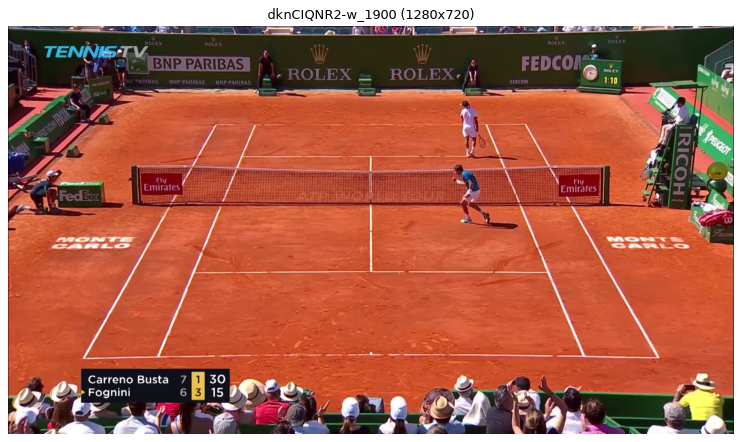

In [3]:
IMAGE_ID = 'dknCIQNR2-w_1900'

det = ClassicalCourtDetector()
img, gt = load(IMAGE_ID)
h, w = img.shape[:2]
show(img, titles=[f'{IMAGE_ID} ({w}x{h})'], size=10)

## 2. 코트 모델

모델 좌표계는 약 1px ≈ 1cm이다. 파란 선은 실제로 칠해진 선분 9개(`MODEL_SEGMENTS`), 빨간 점선은 선이 **없어야 하는** 구간(`EMPTY_SEGMENTS`, v2)이다.
숫자는 키포인트 인덱스(`MODEL_KEYPOINTS`, `WORLD_COURT_POINTS`와 같은 순서)이다.

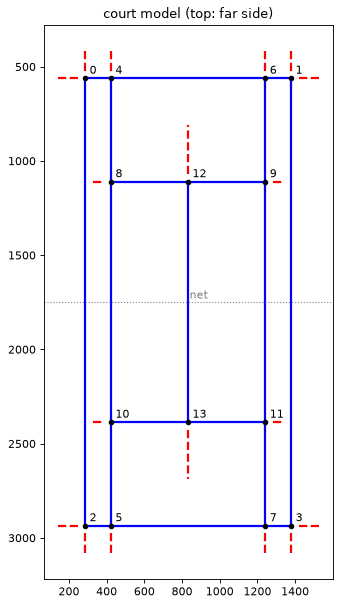

In [4]:
fig, ax = plt.subplots(figsize=(5, 9))
for (x1, y1), (x2, y2) in MODEL_SEGMENTS:
    ax.plot([x1, x2], [y1, y2], 'b-', lw=2)
for (x1, y1), (x2, y2) in EMPTY_SEGMENTS:
    ax.plot([x1, x2], [y1, y2], 'r--', lw=2)
for i, (x, y) in enumerate(MODEL_KEYPOINTS):
    ax.plot(x, y, 'ko', ms=4)
    ax.annotate(str(i), (x, y), textcoords='offset points', xytext=(4, 4))
ax.axhline((561 + 2935) / 2, color='gray', lw=1, ls=':')
ax.text(840, 1730, 'net', color='gray')
ax.set_aspect('equal')
ax.invert_yaxis()
ax.set_title('court model (top: far side)')
plt.show()

## 3.1 라인 픽셀 검출 — `detect_line_pixels`

### (a) 국소 대비 테스트

코트 라인은 "양옆보다 밝고 폭이 좁은 띠"이다. 먼저 코트 가운데를 세로로 지나는 밝기 프로파일을 보자.
베이스라인, 서비스라인, 네트가 폭이 좁은 봉우리로 나타난다. 픽셀 p에서 τ만큼 떨어진 양쪽 이웃이 둘 다 충분히 어두우면 라인 후보이다.

```
g(p) − n > max(c_abs, c_rel · n)   (n = 양쪽 이웃 각각),   g(p) > b_min
```

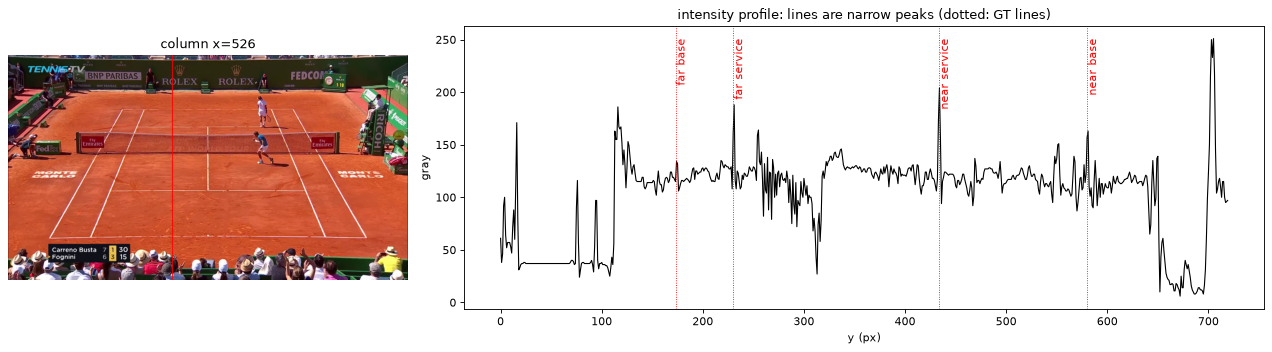

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.int16)

# a column through the middle of the left service boxes (crosses all horizontal lines and the net)
x = int(round((gt[8][0] + gt[12][0]) / 2))
profile = gray[:, x]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 2]})
vis = img.copy()
cv2.line(vis, (x, 0), (x, h - 1), (255, 0, 0), 2)
axes[0].imshow(vis)
axes[0].axis('off')
axes[0].set_title(f'column x={x}')
axes[1].plot(profile, 'k-', lw=1)
for (i, j), name in [((0, 1), 'far base'), ((8, 9), 'far service'), ((10, 11), 'near service'), ((2, 3), 'near base')]:
    (x0, y0), (x1, y1) = gt[i], gt[j]
    y = y0 + (y1 - y0) * (x - x0) / (x1 - x0)  # GT line at this column
    axes[1].axvline(y, color='r', lw=0.8, ls=':')
    axes[1].text(y, profile.max(), name, rotation=90, va='top', color='r')
axes[1].set_xlabel('y (px)')
axes[1].set_ylabel('gray')
axes[1].set_title('intensity profile: lines are narrow peaks (dotted: GT lines)')
plt.tight_layout()
plt.show()

가로 방향 이웃(τx=8)으로 검사하면 **세로 방향** 라인(사이드라인)이, 세로 방향 이웃(τy=4)으로 검사하면 **가로 방향** 라인(베이스라인, 서비스라인)이 잡힌다. 최종 후보는 둘의 합집합이다.

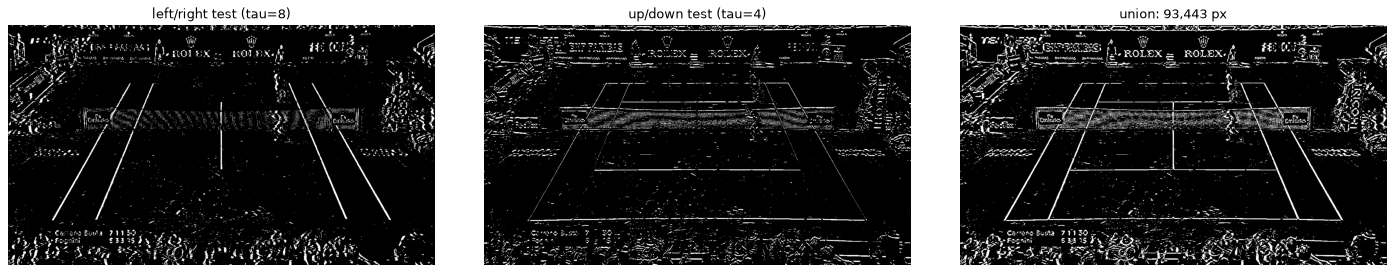

In [6]:
def contrast_test(gray, axis, tau, c, r):
    fwd = np.roll(gray, tau, axis=axis)
    bwd = np.roll(gray, -tau, axis=axis)
    return (gray - fwd > np.maximum(c, r * fwd)) & (gray - bwd > np.maximum(c, r * bwd))

tx, ty = det.line_tau
c, r = det.line_min_contrast, det.line_rel_contrast
test_x = contrast_test(gray, 1, tx, c, r)  # left / right neighbors -> vertical lines
test_y = contrast_test(gray, 0, ty, c, r)  # up / down neighbors -> horizontal lines
contrast_mask = (gray > det.line_min_brightness) & (test_x | test_y)

show(test_x, test_y, contrast_mask, cols=3, size=6,
     titles=[f'left/right test (tau={tx})', f'up/down test (tau={ty})', f'union: {contrast_mask.sum():,} px'])

### (b) Structure tensor coherence 필터

대비 테스트만으로는 관중석, 글자, 바닥 질감도 많이 통과한다. 구조 텐서로 국소 방향이 한쪽으로 정렬된 정도(coherence ∈ [0, 1])를 구해서 **coherence > 0.5**인 픽셀만 남긴다.

```
J = Gσ * [gx²  gx·gy; gx·gy  gy²]   (σ = 3)
coherence = ((Jxx − Jyy)² + 4Jxy²) / (Jxx + Jyy)²
```

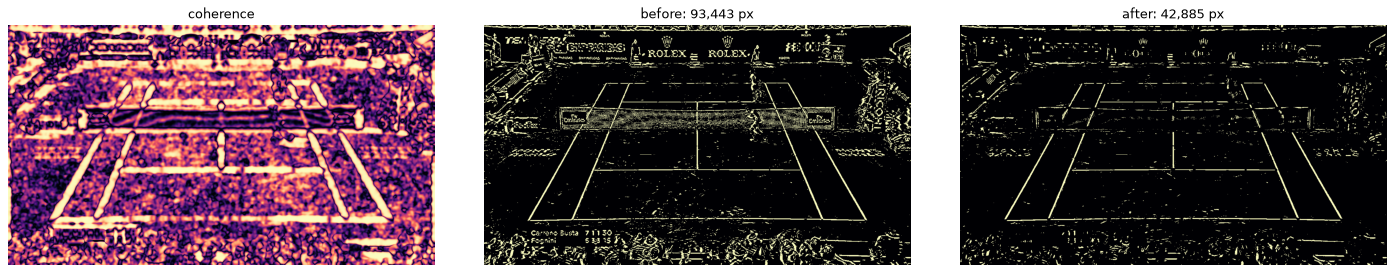

In [7]:
g = gray.astype(np.float32)
gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
sigma = det.coherence_sigma
jxx = cv2.GaussianBlur(gx * gx, (0, 0), sigma)
jyy = cv2.GaussianBlur(gy * gy, (0, 0), sigma)
jxy = cv2.GaussianBlur(gx * gy, (0, 0), sigma)
coherence = ((jxx - jyy) ** 2 + 4 * jxy ** 2) / ((jxx + jyy) ** 2 + 1e-6)

mask = det.detect_line_pixels(img)  # = contrast_mask & (coherence > 0.5)
assert np.array_equal(mask > 0, contrast_mask & (coherence > det.min_coherence))

show(coherence, contrast_mask, mask > 0, cols=3, size=6, cmap='magma',
     titles=['coherence', f'before: {contrast_mask.sum():,} px', f'after: {(mask > 0).sum():,} px'])

관중석이나 광고판이 있는 위쪽을 확대해서 보면 차이가 더 잘 보인다.

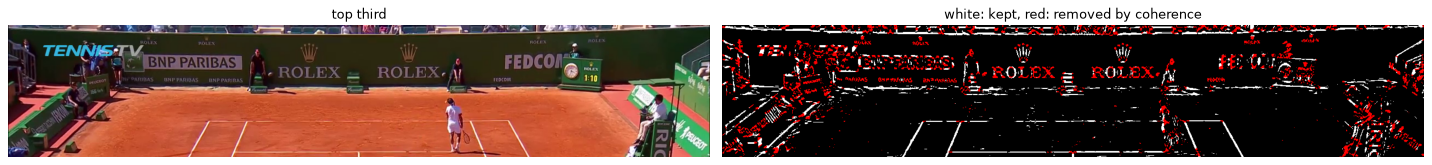

In [8]:
crop = slice(0, h // 3)
removed = np.zeros((h, w, 3), np.uint8)
removed[contrast_mask & (mask == 0)] = (255, 0, 0)
removed[mask > 0] = (255, 255, 255)
show(img[crop], removed[crop], cols=2, size=9, titles=['top third', 'white: kept, red: removed by coherence'])

## 3.2 직선 검출과 분류 — `detect_lines`

1. `HoughLinesP`로 선분을 얻는다(왼쪽, 선분마다 다른 색).
2. 방향 차이 2° 이내이고 끝점이 6px 이내이면 같은 직선으로 묶어서 TLS로 다시 맞춘다.
3. 수평에서 20° 미만이면 **수평 계열**(빨강), 25° 초과면 **수직 계열**(파랑)으로 나눈다. 계열별로 누적 길이 상위 15개만 남긴다(오른쪽).

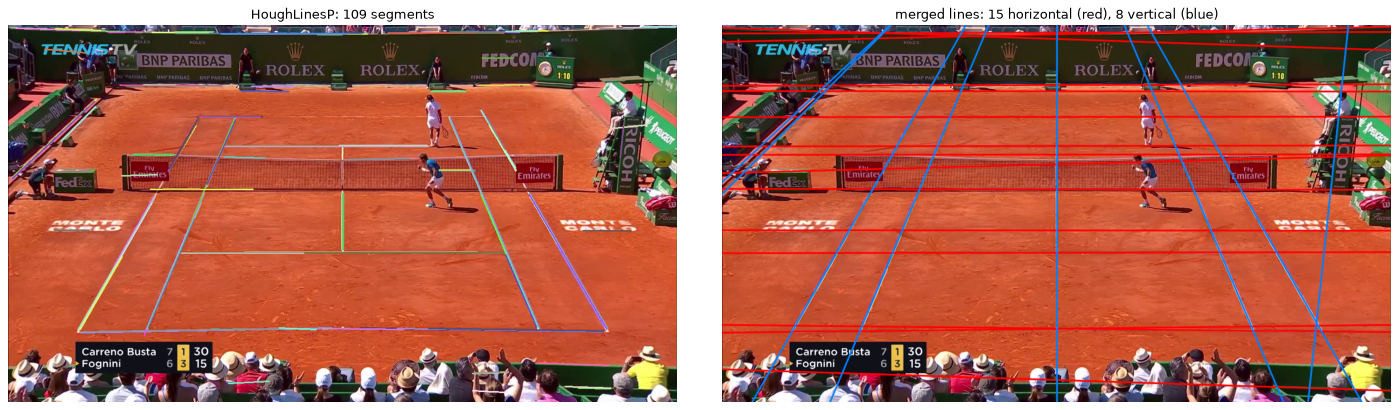

In [9]:
segs = cv2.HoughLinesP(mask, 1, np.pi / 180, det.hough_threshold,
                       minLineLength=det.min_line_length, maxLineGap=det.max_line_gap).reshape(-1, 4)
rng = np.random.default_rng(0)
vis_segs = img.copy()
for x1, y1, x2, y2 in segs:
    cv2.line(vis_segs, (int(x1), int(y1)), (int(x2), int(y2)), tuple(int(v) for v in rng.integers(64, 256, 3)), 2)

horizontal, vertical = det.detect_lines(mask)
vis_lines = draw_lines(img, horizontal, (255, 0, 0))
vis_lines = draw_lines(vis_lines, vertical, (0, 128, 255))

show(vis_segs, vis_lines, size=9,
     titles=[f'HoughLinesP: {len(segs)} segments',
             f'merged lines: {len(horizontal)} horizontal (red), {len(vertical)} vertical (blue)'])

## 3.3 가설 생성 — `hypothesize`

이미지 수평선 2개 + 수직선 2개를 모델 수평선 2개 + 수직선 2개에 **순서를 보존해** 대응시키고, 교점 4개로 H를 계산한다.
모든 조합을 배치로 한 번에 푼다. 대부분은 엉터리 가설이다. 아래는 무작위로 뽑은 6개이다.

hypotheses: 176,400  (0.30s)
upper bound: C(15,2)*C(4,2)*C(8,2)*C(5,2) = 176,400


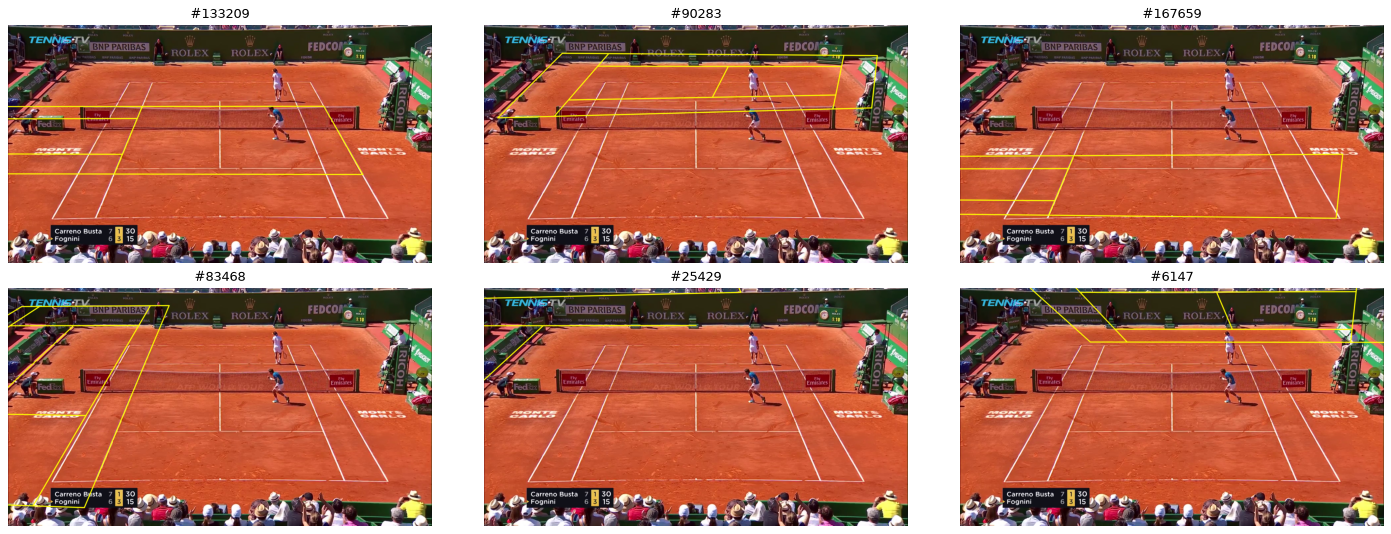

In [10]:
import time
from math import comb

t0 = time.time()
H_all = det.hypothesize(horizontal, vertical, (h, w))
print(f'hypotheses: {len(H_all):,}  ({time.time() - t0:.2f}s)')
print(f'upper bound: C({len(horizontal)},2)*C(4,2)*C({len(vertical)},2)*C(5,2) = '
      f'{comb(len(horizontal), 2) * 6 * comb(len(vertical), 2) * 10:,}')

idx = np.random.default_rng(1).choice(len(H_all), 6, replace=False)
show(*[draw_court(img, H_all[i]) for i in idx], cols=3, size=6, titles=[f'#{i}' for i in idx])

## 3.4 타당성 필터 — `plausible`

**(a) 기하 조건**: 코트 네 모서리가 카메라 앞에 있고, 좌우와 상하 순서가 맞고, 가까운 쪽이 더 넓고, 크기가 적당해야 한다.

**(b) 카메라 조건(v3)**: H ~ K[r₁ r₂ t]에서 초점거리 f와 카메라 위치 C를 복원한다. f가 실수로 존재하지 않거나(1/f² ≤ 0), 중계 카메라 범위를 벗어나면 버린다.

먼저 정답 호모그래피(GT 키포인트로 계산)에서 카메라를 복원해 보자.

GT camera: f = 2446px (1.91 x image width), height = 9.2m, 25.1m behind the near baseline, x offset from the center = +0.0m


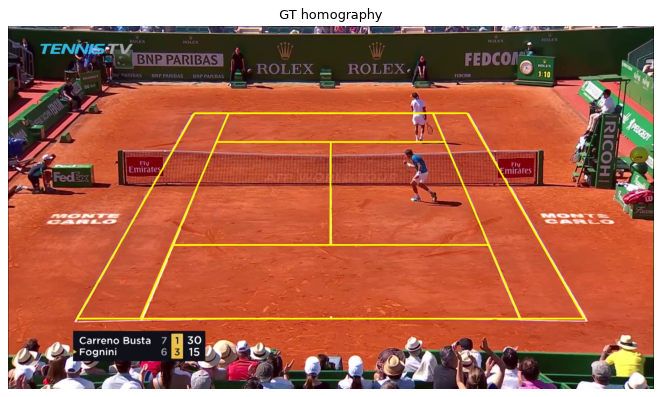

In [11]:
H_gt = gt_homography(gt)
f_gt, C_gt = camera_from_homographies(H_gt, (h, w))
print(f'GT camera: f = {f_gt[0]:.0f}px ({f_gt[0] / w:.2f} x image width), '
      f'height = {-C_gt[0, 2] / 100:.1f}m, '
      f'{(C_gt[0, 1] - Y_BOTTOM) / 100:.1f}m behind the near baseline, '
      f'x offset from the center = {(C_gt[0, 0] - 832) / 100:+.1f}m')
show(draw_court(img, H_gt), titles=['GT homography'], size=9)

all: 176,400  ->  geometric: 83,262  ->  + camera: 47,541
rejected by camera: 35,721 (no real focal length: 15,729)


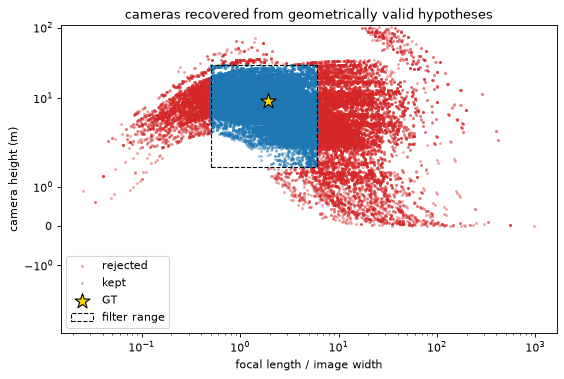

In [12]:
geo_ok = ClassicalCourtDetector(focal_range=None).plausible(H_all, (h, w))  # geometric only
ok = det.plausible(H_all, (h, w))  # geometric + camera
print(f'all: {len(H_all):,}  ->  geometric: {geo_ok.sum():,}  ->  + camera: {ok.sum():,}')

f, C = camera_from_homographies(H_all[geo_ok], (h, w))
cam_ok = ok[geo_ok]
print(f'rejected by camera: {(~cam_ok).sum():,} (no real focal length: {np.isnan(f).sum():,})')

fig, ax = plt.subplots(figsize=(8, 5))
valid = ~np.isnan(f)
for sel, color, label in [(valid & ~cam_ok, 'tab:red', 'rejected'), (cam_ok, 'tab:blue', 'kept')]:
    ax.scatter(f[sel] / w, -C[sel, 2] / 100, s=3, c=color, alpha=0.3, label=label)
ax.scatter(f_gt / w, -C_gt[:, 2] / 100, s=200, c='gold', marker='*', edgecolors='k', label='GT', zorder=3)
ax.add_patch(plt.Rectangle((det.focal_range[0], det.camera_height_range[0] / 100),
                           det.focal_range[1] - det.focal_range[0],
                           (det.camera_height_range[1] - det.camera_height_range[0]) / 100,
                           fill=False, ls='--', color='k', label='filter range'))
ax.set_xscale('log')
ax.set_yscale('symlog')
ax.set_xlabel('focal length / image width')
ax.set_ylabel('camera height (m)')
ax.set_title('cameras recovered from geometrically valid hypotheses')
ax.legend()
plt.show()

## 3.5 점수 — `score_homographies`

마스크의 distance transform(가장 가까운 라인 픽셀까지 거리)을 미리 구해 두고, 모델 선분 위의 점들을 투영해서 센다.

```
score = hit − 0.5 · miss − 1.0 · empty_hit
```

scored 47,541 hypotheses in 0.76s


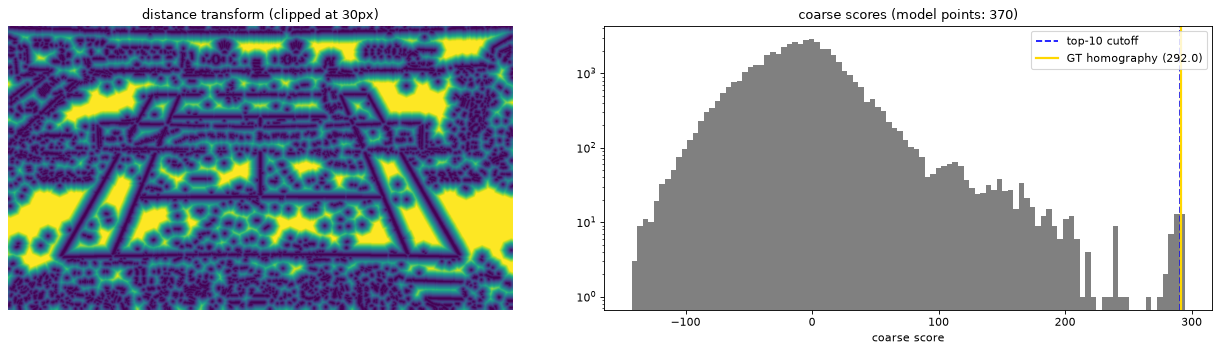

In [13]:
H = H_all[ok]
dist_map = cv2.distanceTransform(255 - mask, cv2.DIST_L2, 3)

t0 = time.time()
scores = det.score_homographies(H, dist_map, det.coarse_points, det.coarse_empty_points)
top = np.argsort(-scores)[:det.top_k]
print(f'scored {len(H):,} hypotheses in {time.time() - t0:.2f}s')

score_gt = det.score_homographies(H_gt[None], dist_map, det.coarse_points, det.coarse_empty_points)[0]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].imshow(np.minimum(dist_map, 30), cmap='viridis')
axes[0].axis('off')
axes[0].set_title('distance transform (clipped at 30px)')
axes[1].hist(scores, bins=100, color='gray')
axes[1].axvline(scores[top[-1]], color='b', ls='--', label=f'top-{det.top_k} cutoff')
axes[1].axvline(score_gt, color='gold', lw=2, label=f'GT homography ({score_gt:.1f})')
axes[1].set_yscale('log')
axes[1].set_xlabel('coarse score')
axes[1].set_title(f'coarse scores (model points: {len(det.coarse_points)})')
axes[1].legend()
plt.tight_layout()
plt.show()

상위 가설들이다. 보통 상위권은 정답 근처의 비슷한 해들이다.

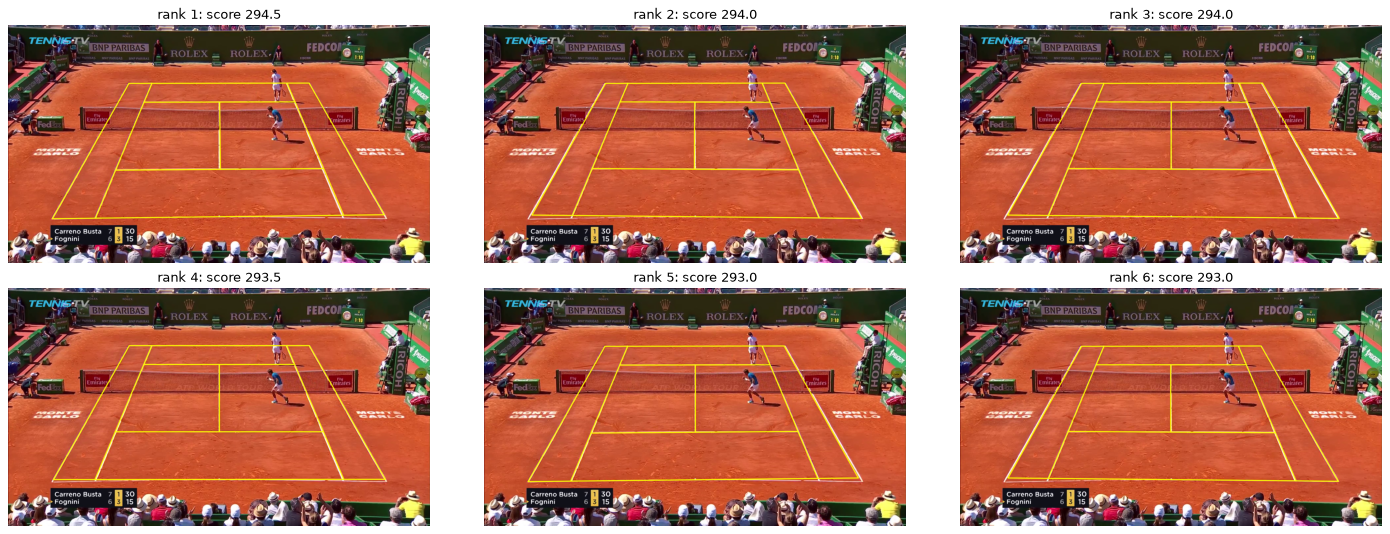

In [14]:
show(*[draw_court(img, H[k]) for k in top[:6]], cols=3, size=6,
     titles=[f'rank {i + 1}: score {scores[k]:.1f}' for i, k in enumerate(top[:6])])

점수가 어떻게 매겨지는지 점 단위로 본다. 1위 가설과 무작위 가설을 비교한다(fine 샘플, 10 단위 간격).

- 초록: hit (라인 픽셀 3px 이내) / 빨강: miss / 자홍: 빈 영역인데 라인 픽셀이 있음(감점) / 회색: 빈 영역, 라인 없음(정상)

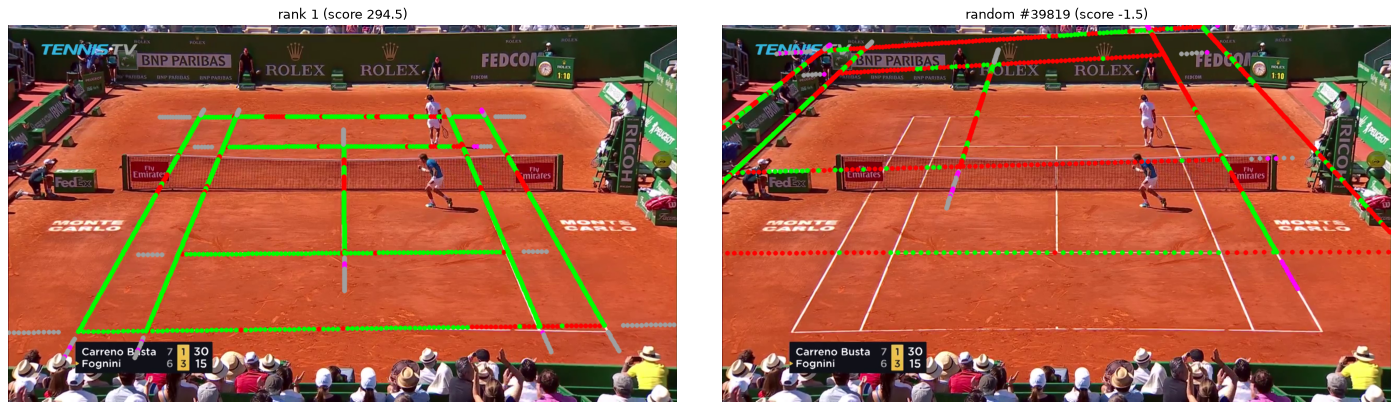

In [15]:
k_rand = np.random.default_rng(2).choice(len(H))
pts, empty = det.fine_points, det.fine_empty_points
show(draw_points(img, H[top[0]], pts, empty, dist_map), draw_points(img, H[k_rand], pts, empty, dist_map),
     size=9, titles=[f'rank 1 (score {scores[top[0]]:.1f})', f'random #{k_rand} (score {scores[k_rand]:.1f})'])

## 3.6 정밀화 — `refine`

coarse 가설은 이미지 직선 교점 4개로만 만든 것이라 오차가 있다. 투영된 각 모델 선분 주변 ±8px 띠의 라인 픽셀을 모아 직선을 다시 맞추고(2.5px 이내로 한 번 더), 모든 교점으로 H를 다시 계산한다. 이를 3회 반복한다.

아래 왼쪽은 첫 반복에서 각 모델 선분에 배정된 라인 픽셀이다(선분마다 다른 색).

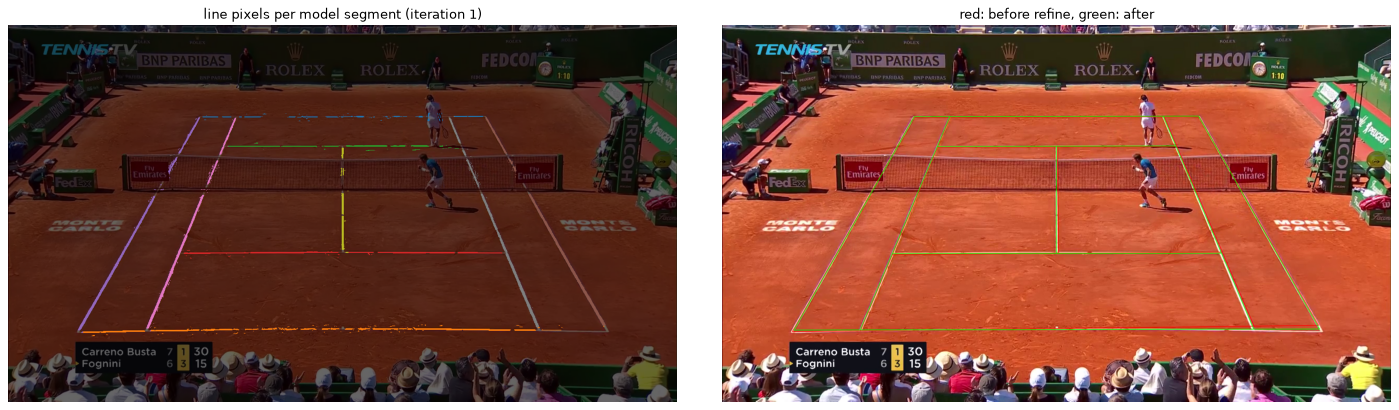

In [16]:
ys, xs = np.nonzero(mask)
mask_points = np.stack([xs, ys], axis=1).astype(np.float64)
H0 = H[top[0]]

vis_band = (img * 0.4).astype(np.uint8)
palette = plt.cm.tab10(np.arange(len(MODEL_SEGMENTS)))[:, :3] * 255
for i, segment in enumerate(MODEL_SEGMENTS):
    (p0, p1), _ = project(H0, np.array(segment, dtype=np.float64))
    line = det.segment_to_line([*p0, *p1])
    d = mask_points @ line[:2] + line[2]
    direction = (p1 - p0) / np.linalg.norm(p1 - p0)
    t = (mask_points - p0) @ direction
    near = (np.abs(d) < det.refine_band) & (t > 0) & (t < np.linalg.norm(p1 - p0))
    vis_band[ys[near], xs[near]] = palette[i]

H_ref = det.refine(H0, mask_points, (h, w))
vis_cmp = draw_court(img, H0, color=(255, 0, 0), thickness=1)
vis_cmp = draw_court(vis_cmp, H_ref, color=(0, 255, 0), thickness=1)
show(vis_band, vis_cmp, size=9, titles=['line pixels per model segment (iteration 1)',
                                        'red: before refine, green: after'])

정밀화 전후로 가장 많이 움직인 키포인트 두 곳을 4배 확대했다. 흰 원은 GT(반지름 7px = 정답 판정 거리)이다.

정밀화는 **라인 픽셀**에 맞추는 단계이므로 효과는 "모델 선분 점이 라인 픽셀 중심에서 얼마나 떨어져 있는가"로 재는 것이 정확하다.
GT 라벨 자체에도 1~3px 오차가 있어서, 이미지에 따라 GT 대비 오차가 오히려 조금 늘 수도 있다.

참고로 val 정상 이미지 176장(12장 간격 샘플)에서 coarse 1위 가설에 정밀화를 적용하면 GT 대비 평균 오차는 2.12px → 1.66px, 이미지별 최대 오차 평균은 4.65px → 3.39px가 되고, 81%의 이미지에서 줄었다.

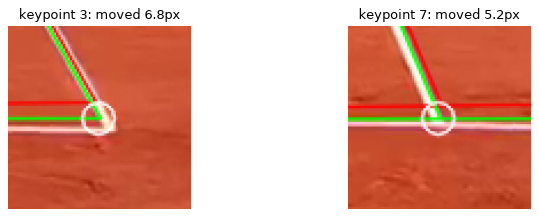

before refine: model points to line pixels mean 1.26px, within 1px 72.5%
after  refine: model points to line pixels mean 0.92px, within 1px 82.5%
keypoint error vs GT (visible 14 points): before mean 3.91px / max 6.68px  ->  after mean 1.54px / max 2.04px


In [17]:
def zoom(vis, center, half=40, scale=4):
    cx, cy = map(int, np.round(center))
    patch = vis[max(cy - half, 0):cy + half, max(cx - half, 0):cx + half]
    return cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)

vis_zoom = vis_cmp.copy()
for g_ in gt:
    cv2.circle(vis_zoom, tuple(map(round, g_)), 7, (255, 255, 255), 1, cv2.LINE_AA)
kp0, _ = project(H0, MODEL_KEYPOINTS)
kp1, _ = project(H_ref, MODEL_KEYPOINTS)
inside = (gt[:, 0] >= 0) & (gt[:, 0] < w) & (gt[:, 1] >= 0) & (gt[:, 1] < h)
moved = np.argsort(-np.where(inside, np.linalg.norm(kp1 - kp0, axis=1), -1))[:2]
show(*[zoom(vis_zoom, kp1[i]) for i in moved], size=5,
     titles=[f'keypoint {i}: moved {np.linalg.norm(kp1[i] - kp0[i]):.1f}px' for i in moved])


def line_alignment(H_):
    # mean distance from projected model points (inside the image) to the nearest line pixel
    p, _ = project(H_, det.fine_points)
    p = np.round(p).astype(int)
    p = p[(p[:, 0] >= 0) & (p[:, 0] < w) & (p[:, 1] >= 0) & (p[:, 1] < h)]
    d_ = dist_map[p[:, 1], p[:, 0]]
    return d_.mean(), (d_ <= 1).mean()


for name, H_ in [('before', H0), ('after', H_ref)]:
    mean_d, within1 = line_alignment(H_)
    print(f'{name:6s} refine: model points to line pixels mean {mean_d:.2f}px, within 1px {within1:.1%}')
e0 = np.linalg.norm(kp0 - gt, axis=1)[inside]
e1 = np.linalg.norm(kp1 - gt, axis=1)[inside]
print(f'keypoint error vs GT (visible {inside.sum()} points): '
      f'before mean {e0.mean():.2f}px / max {e0.max():.2f}px  ->  after mean {e1.mean():.2f}px / max {e1.max():.2f}px')

상위 10개 가설을 모두 정밀화하고 fine 점수(10 단위 샘플)로 다시 평가해서 최고 점수를 고른다. coarse 순위와 최종 순위가 다를 수 있다.

In [18]:
refined = []
for rank, k in enumerate(top):
    H_k = det.refine(H[k], mask_points, (h, w))
    fine = det.score_homographies(H_k[None], dist_map, det.fine_points, det.fine_empty_points)[0]
    refined.append((fine, rank, H_k))
    print(f'coarse rank {rank + 1:2d}: coarse {scores[k]:6.1f}  ->  fine {fine:6.1f}')
best_fine, best_rank, best_H = max(refined, key=lambda t: t[0])
print(f'best: coarse rank {best_rank + 1}, normalized score {best_fine / len(det.fine_points):.3f}')

coarse rank  1: coarse  294.5  ->  fine 1219.5
coarse rank  2: coarse  294.0  ->  fine 1221.0
coarse rank  3: coarse  294.0  ->  fine 1219.5
coarse rank  4: coarse  293.5  ->  fine 1221.0
coarse rank  5: coarse  293.0  ->  fine 1221.0
coarse rank  6: coarse  293.0  ->  fine 1219.5
coarse rank  7: coarse  293.0  ->  fine 1219.5
coarse rank  8: coarse  292.0  ->  fine 1221.0
coarse rank  9: coarse  291.5  ->  fine 1221.0


coarse rank 10: coarse  291.0  ->  fine 1221.0
best: coarse rank 2, normalized score 0.834


## 3.7 출력

최종 H로 14개 키포인트를 투영한다. 화면 안이면 score 1, 밖이면 0이다. 위에서 풀어 쓴 결과가 `det(img)`를 한 번에 호출한 결과와 같은지 확인한다.

- 초록: 정답(TP), 빨강: 7px 초과(FN, GT까지 선), 주황: GT가 없는데 화면 안(FP), 흰 원: GT

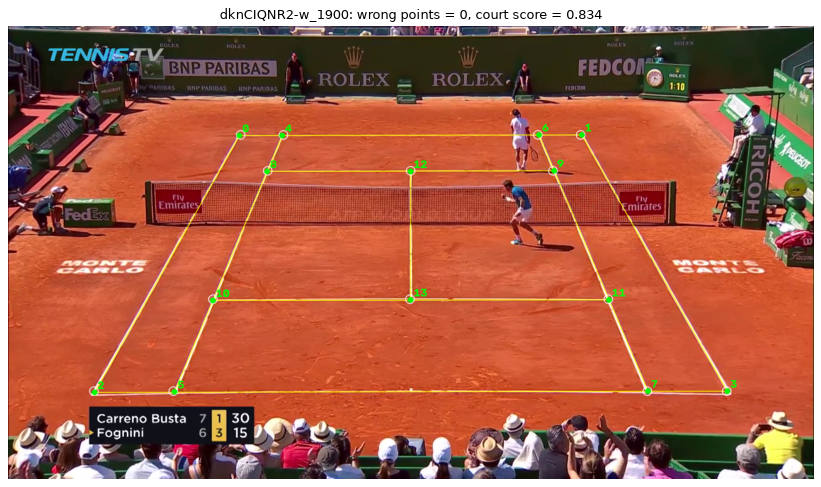

 0  (  367.2,  173.8)  score 1  tp  err 1.93px
 1  (  910.6,  173.3)  score 1  tp  err 1.63px
 2  (  137.4,  581.5)  score 1  tp  err 2.05px
 3  ( 1142.0,  579.9)  score 1  tp  err 1.04px
 4  (  435.4,  173.7)  score 1  tp  err 1.75px
 5  (  263.5,  581.3)  score 1  tp  err 2.00px
 6  (  842.6,  173.4)  score 1  tp  err 1.59px
 7  ( 1016.3,  580.1)  score 1  tp  err 1.32px
 8  (  411.4,  230.7)  score 1  tp  err 0.98px
 9  (  866.9,  230.3)  score 1  tp  err 1.90px
10  (  325.0,  435.6)  score 1  tp  err 1.60px
11  (  954.2,  434.7)  score 1  tp  err 1.43px
12  (  638.9,  230.5)  score 1  tp  err 0.52px
13  (  639.4,  435.2)  score 1  tp  err 1.83px


In [19]:
keypoints, kp_scores = det(img)
assert np.allclose(det.matrix, best_H)

vis_out, num_wrong = draw_result(img, det.matrix, keypoints, kp_scores, gt)
show(vis_out, size=11, titles=[f'{IMAGE_ID}: wrong points = {num_wrong}, court score = {det.score:.3f}'])

status, _ = evaluate(keypoints, kp_scores, gt, (h, w))
for i, ((x, y), sc, (s, e)) in enumerate(zip(keypoints, kp_scores, status)):
    print(f'{i:2d}  ({x:7.1f}, {y:6.1f})  score {sc:.0f}  {s}' + (f'  err {e:.2f}px' if e is not None else ''))

---

## 부록: 버전별 비교 (v1 → v2 → v3)

같은 클래스에서 파라미터만 바꿔서 이전 버전을 재현한다.

| 버전 | 설정 |
| --- | --- |
| v1 | 절대 대비(밝기 > 110, 대비 > 15), 빈 영역 페널티 없음, 카메라 필터 없음 |
| v2 | + 상대 대비(`g − n > max(8, 0.15·n)`, 밝기 > 40), 빈 영역 페널티 |
| v3 | + 카메라 타당성 필터 (현재 기본값) |

사례:
- `XGsWUnmQtII_550` (v1 실패): 네트 테이프를 베이스라인으로 착각 → v2의 빈 영역 페널티와 상대 대비로 해결
- `RZ5R-0MmPns_3150` (v1 실패): 그늘 속 먼 쪽 베이스라인 누락 → v2의 상대 대비로 해결
- `M3IuThopUJU_1200` (v2 실패): 코트를 네트 띠 안에 압축한 해 → v3의 카메라 필터로 해결

XGsWUnmQtII_550


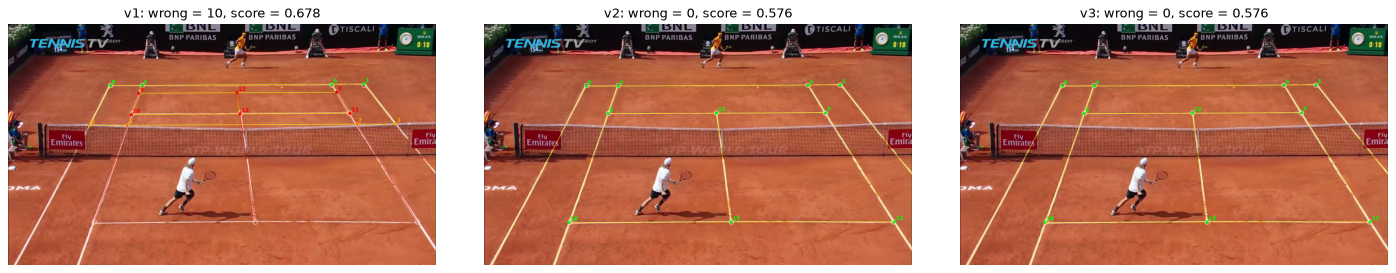

RZ5R-0MmPns_3150


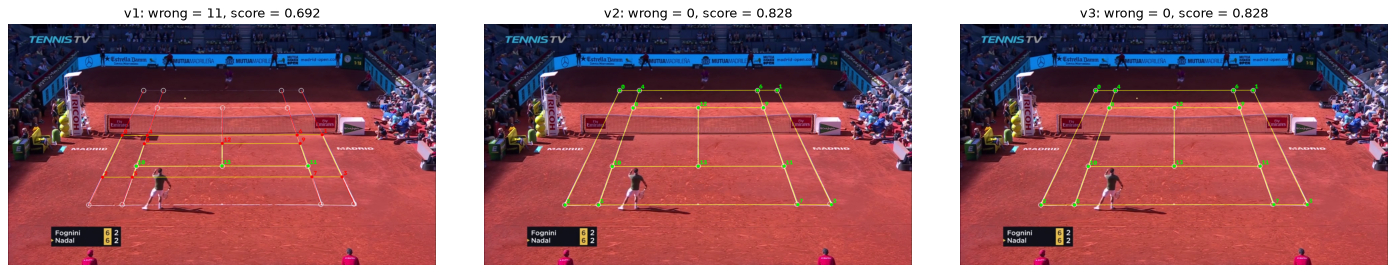

M3IuThopUJU_1200


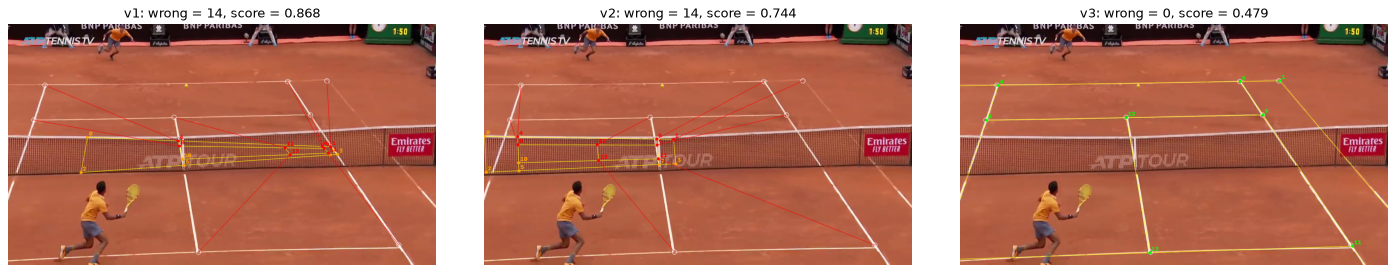

In [20]:
VERSIONS = {
    'v1': dict(line_min_brightness=110, line_min_contrast=15, line_rel_contrast=0,
               empty_penalty=0, focal_range=None),
    'v2': dict(focal_range=None),
    'v3': dict(),
}
CASES = ['XGsWUnmQtII_550', 'RZ5R-0MmPns_3150', 'M3IuThopUJU_1200']

runs = {}
for image_id in CASES:
    case_img, case_gt = load(image_id)
    vis, titles = [], []
    for name, cfg in VERSIONS.items():
        d = ClassicalCourtDetector(**cfg)
        kps, scs = d(case_img)
        runs[image_id, name] = (d, kps, scs)
        v, n = draw_result(case_img, d.matrix, kps, scs, case_gt)
        vis.append(v)
        titles.append(f'{name}: wrong = {n}, score = {d.score:.3f}')
    print(image_id)
    show(*vis, cols=3, size=6, titles=titles)

### XGsWUnmQtII_550 — 빈 영역 페널티와 카메라 필터

v1 해와 v3 해를 **v3 점수 기준**으로 점 단위 비교한다. v1 해는 네트 테이프를 먼 쪽 서비스라인으로 쓰는데, 테이프는 복식 사이드라인 밖까지 이어지므로 빈 영역(자홍) 감점을 받는다.

그런데 감점을 받고도 **v1 해의 fine 점수가 정답보다 여전히 높다**(아래 수치). 정답 쪽은 가까운 코트 라인이 선수와 네트에 가려 miss(빨강)가 많기 때문이다.

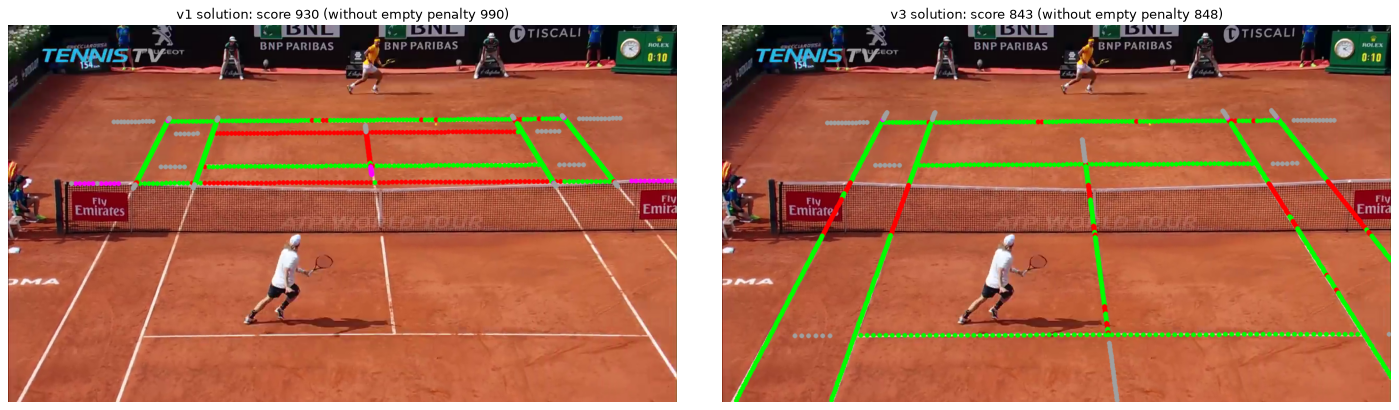

In [21]:
image_id = 'XGsWUnmQtII_550'
case_img, _ = load(image_id)
d3 = ClassicalCourtDetector()
case_mask = d3.detect_line_pixels(case_img)
case_dist = cv2.distanceTransform(255 - case_mask, cv2.DIST_L2, 3)
vis, titles = [], []
for name in ['v1', 'v3']:
    H_v = runs[image_id, name][0].matrix
    s = d3.score_homographies(H_v[None], case_dist, d3.fine_points, d3.fine_empty_points)[0]
    s0 = ClassicalCourtDetector(empty_penalty=0).score_homographies(
        H_v[None], case_dist, d3.fine_points, d3.fine_empty_points)[0]
    vis.append(draw_points(case_img, H_v, d3.fine_points, d3.fine_empty_points, case_dist))
    titles.append(f'{name} solution: score {s:.0f} (without empty penalty {s0:.0f})')
show(*vis, size=9, titles=titles)

그러면 v2는 왜 맞췄을까? 버전별로 v1 해 근처(키포인트 최대 10px 이내)의 coarse 가설이 몇 위인지 보면 알 수 있다.
v2에서는 마스크가 바뀌면서 v1 해의 coarse 순위가 상위 10개 밖으로 밀려서 **정밀화 대상에 들지 못했을 뿐**이다. 즉 v2의 해결은 coarse 순위 차이에 기대는 것이라 불안정하다.
v3의 카메라 필터는 이 해를 아예 버린다. 복원된 카메라가 초점거리 7.7배 화면 폭, 코트 뒤 118m라서 중계 카메라 범위를 벗어난다.

In [22]:
H_v1 = runs[image_id, 'v1'][0].matrix
K_v1, _ = project(H_v1, MODEL_KEYPOINTS)
for name, cfg in VERSIONS.items():
    d = ClassicalCourtDetector(**cfg)
    m = d.detect_line_pixels(case_img)
    hz, vt = d.detect_lines(m)
    H_c = d.hypothesize(hz, vt, case_img.shape[:2])
    H_c = H_c[d.plausible(H_c, case_img.shape[:2])]
    s = d.score_homographies(H_c, cv2.distanceTransform(255 - m, cv2.DIST_L2, 3),
                             d.coarse_points, d.coarse_empty_points)
    near_v1 = np.linalg.norm(project(H_c, MODEL_KEYPOINTS)[0] - K_v1, axis=2).max(1) < 10
    ranks = np.where(near_v1[np.argsort(-s)])[0] + 1
    print(f'{name}: {len(H_c):,} plausible hypotheses, near the v1 solution: {near_v1.sum()}, '
          f'best coarse rank {ranks[0] if len(ranks) else "-"} (top-{d.top_k} are refined)')

f_v, C_v = camera_from_homographies(H_v1, case_img.shape[:2])
print(f'camera of the v1 solution: f = {f_v[0] / case_img.shape[1]:.1f} x width, height = {-C_v[0, 2] / 100:.1f}m, '
      f'{(C_v[0, 1] - Y_BOTTOM) / 100:.0f}m behind the near baseline')

v1: 22,747 plausible hypotheses, near the v1 solution: 7, best coarse rank 1 (top-10 are refined)


v2: 29,734 plausible hypotheses, near the v1 solution: 10, best coarse rank 12 (top-10 are refined)


v3: 13,606 plausible hypotheses, near the v1 solution: 0, best coarse rank - (top-10 are refined)
camera of the v1 solution: f = 7.7 x width, height = 8.2m, 118m behind the near baseline


### RZ5R-0MmPns_3150 — 상대 대비

먼 쪽 절반이 그늘이다. 절대 임계값(v1)에서는 그늘 속 베이스라인이 마스크에서 빠지고, 상대 임계값(v2 이후)에서는 남는다.
아래 출력의 밝기 프로파일을 보면 먼 쪽 베이스라인의 밝기는 약 60, 바닥은 약 30이다. 대비(약 30)는 충분하지만 v1의 최소 밝기 110에 걸린다.

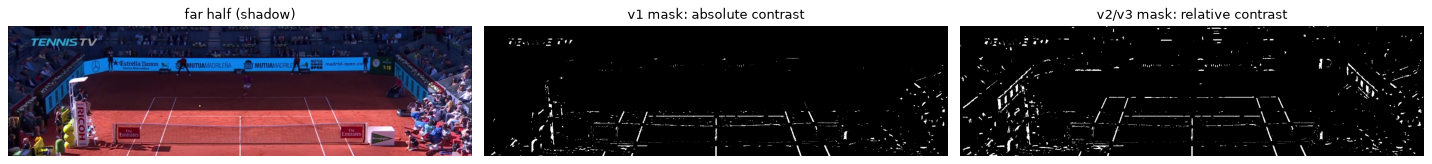

far baseline at x=640: gray profile around y=198: [30, 29, 29, 29, 30, 30, 30, 30, 31, 30, 30, 30, 30, 30, 39, 62, 59, 32, 29, 31, 32, 32, 35, 33, 32, 31, 30, 33, 36, 37]


In [23]:
image_id = 'RZ5R-0MmPns_3150'
case_img, case_gt = load(image_id)
top_half = slice(0, case_img.shape[0] // 2)
m1 = ClassicalCourtDetector(**VERSIONS['v1']).detect_line_pixels(case_img)
m3 = ClassicalCourtDetector().detect_line_pixels(case_img)
show(case_img[top_half], m1[top_half], m3[top_half], cols=3, size=6,
     titles=['far half (shadow)', 'v1 mask: absolute contrast', 'v2/v3 mask: relative contrast'])

cg = cv2.cvtColor(case_img, cv2.COLOR_RGB2GRAY)
x = int(round((case_gt[0][0] + case_gt[1][0]) / 2))
y = int(round((case_gt[0][1] + case_gt[1][1]) / 2))
col = cg[max(y - 15, 0):y + 15, x]
print(f'far baseline at x={x}: gray profile around y={y}:', col.tolist())

### M3IuThopUJU_1200 — 카메라 필터

v2 해에서 카메라를 복원하면 초점거리가 실수로 존재하지 않거나(nan) 범위를 크게 벗어난다. 이런 투영을 만드는 카메라는 없다.

In [24]:
image_id = 'M3IuThopUJU_1200'
case_img, case_gt = load(image_id)
ch, cw = case_img.shape[:2]
for name, H_v in [('v2', runs[image_id, 'v2'][0].matrix), ('v3', runs[image_id, 'v3'][0].matrix),
                  ('GT', gt_homography(case_gt))]:
    f_v, C_v = camera_from_homographies(H_v, (ch, cw))
    print(f'{name}: f = {f_v[0] / cw:.2f} x width, height = {-C_v[0, 2] / 100:.1f}m, '
          f'{(C_v[0, 1] - Y_BOTTOM) / 100:.1f}m behind the near baseline, '
          f'plausible = {bool(ClassicalCourtDetector().plausible(H_v[None], (ch, cw))[0])}')

v2: f = nan x width, height = nanm, nanm behind the near baseline, plausible = False
v3: f = 2.94 x width, height = 7.8m, 17.7m behind the near baseline, plausible = True
GT: f = 2.99 x width, height = 7.9m, 18.0m behind the near baseline, plausible = True
